This study is for checking if ISR and MPI cause high rate (~10%, see parton.ipynb) of jets not matched to outgoing partons from hard scattering.

Events generated with
`PartonLevel:MPI = off`
`PartonLevel:ISR = off`
`PartonLevel:FSR = on`

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [4]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m']

In [5]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_11pthat15_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_15pthat20_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_20pthat25_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_25pthat30_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_30pthat35_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_35pthat40_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_40pthat45_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_45pthat50_noue_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_50pthat1000_noue_rc_truth.txt']

In [6]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/10000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [7]:
np.unique(df['w'])

array([7.14581e-04, 2.26694e-03, 9.46421e-03, 3.97010e-02, 1.76851e-01,
       8.68474e-01, 5.00388e+00, 3.80123e+01, 2.54466e+02])

In [8]:
df = applyCut(df, 'pt>20')

In [9]:
np.unique(df['parton'])

array([-5, -4, -3, -2, -1,  0,  1,  2,  3,  4,  5, 21])

In [11]:
for parton in np.unique(df['parton']):
    prob = sum(df[df.parton==parton]['w'])/sum(df['w'])
    print('parton, prob:', parton, prob)

parton, prob: -5 0.001706945480374728
parton, prob: -4 0.01944592246135058
parton, prob: -3 0.004188135729547441
parton, prob: -2 0.023863704191465853
parton, prob: -1 0.03212483787554016
parton, prob: 0 0.011681182236833662
parton, prob: 1 0.19327939649213224
parton, prob: 2 0.46297852636452375
parton, prob: 3 0.003573085531242452
parton, prob: 4 0.025599905963741343
parton, prob: 5 0.00222495614213907
parton, prob: 21 0.21933340152893036


In [12]:
parton_new = []
for i in range(0, df.shape[0]):
    parton = df.iloc[i]['parton']
    if (parton == 21):
        parton_new.append(6)
    else:
        parton_new.append(parton)

In [13]:
df['parton_new'] = parton_new

In [14]:
df.eval('b_ch = q1*q2', inplace=True)

In [15]:
df_array = []
for parton in np.unique(df['parton_new']):
    df_temp = df[df.parton_new==parton]
    df_array.append(df_temp)

In [16]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

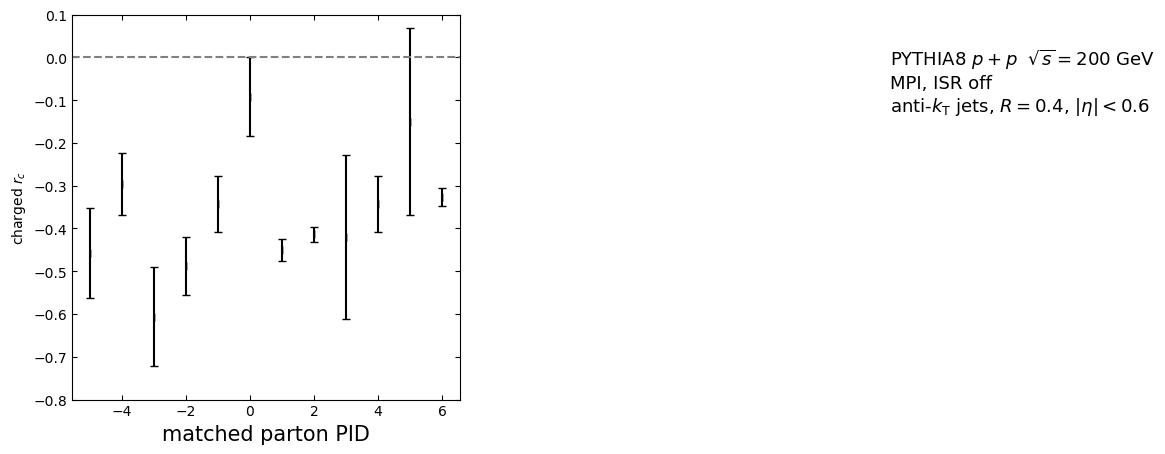

In [18]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(np.unique(df['parton_new']), rc_array, xerr=0, yerr=rc_err_array, capsize=3, ls='none', label='overall', color='k')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel('matched parton PID', fontsize=15)
plt.text(20,-0.125,'PYTHIA8 $p+p$  $\sqrt{s}=200$ GeV\nMPI, ISR off\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
#plt.legend(fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')